# Baseline Models: Random Forest and Isolation Forest

Compare supervised classification with normal-only anomaly detection on the official NSL-KDD training and test split. Run the cells from top to bottom to reproduce the comparison.

1. **Setup:** imports, reproducible seed, and project paths.
2. **Load data:** the 43-column schema and both dataset files.
3. **Labels and sanity checks:** binary targets, Normal/DoS/Probe/R2L/U2R families, unknown labels, and test-only attack types.
4. **Preprocessing:** one-hot encoding and numeric scaling fitted on training data only; exclude labels and difficulty from features.
5. **Random Forest:** supervised training with `class_weight="balanced"`.
6. **Isolation Forest:** fit on normal training traffic and choose its threshold using training scores only.
7. **Overall comparison:** a metrics table, confusion matrices, ROC curves, and precision-recall curves.
8. **Per-category recall:** compare attack families and attack types, including attacks absent from training.
9. **Random Forest feature importance:** inspect which features drive the classifier.
10. **Save results:** export `results/baseline_overall.csv` for a later Transformer comparison on the same split.

Throughout the comparison, **attack = 1** and **normal = 0**. Test labels are reserved for evaluation; they must not influence fitted preprocessing, model selection, or the anomaly threshold.

## 1. Setup

Import the tools needed for both baselines, set a shared random seed, and locate the repository from the current working directory. This works when the notebook starts from either the project root or the `notebooks` folder.

We will use `KDDTrain+.txt` for training and `KDDTest+.txt` for final evaluation. This cell only configures paths; loading, fitting, and saving happen in later sections. Package versions are printed to help reproduce the experiment.

In [1]:
import hashlib
import json
import platform
from datetime import datetime, timezone
import random
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn import metrics
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_JOBS = -1
NORMAL_LABEL = 0
ATTACK_LABEL = 1
random.seed(SEED)
np.random.seed(SEED)
# Pass random_state=SEED to each estimator when we create it.

cwd = Path.cwd().resolve()
PROJECT_DIR = next(
    (path for path in (cwd, *cwd.parents)
     if (path / 'data' / 'raw').is_dir() and (path / 'src').is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError('Start this notebook inside the TRANSFORMER repository.')

RAW_DIR = PROJECT_DIR / 'data' / 'raw'
TRAIN_PATH = RAW_DIR / 'KDDTrain+.txt'
TEST_PATH = RAW_DIR / 'KDDTest+.txt'
RESULTS_DIR = PROJECT_DIR / 'results'
BASELINE_RESULTS_PATH = RESULTS_DIR / 'baseline_overall.csv'
NOTEBOOK_PATH = PROJECT_DIR / 'notebooks' / '03_baseline_models.ipynb'

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

print(f'Python {platform.python_version()} | NumPy {np.__version__} | '
      f'pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'Seed: {SEED} | Target convention: normal={NORMAL_LABEL}, attack={ATTACK_LABEL}')
print(f'Project: {PROJECT_DIR}')
print(f'Notebook: {NOTEBOOK_PATH}')
print(f'Train:   {TRAIN_PATH}')
print(f'Test:    {TEST_PATH}')
print(f'Results: {BASELINE_RESULTS_PATH}')

Python 3.14.0 | NumPy 2.5.2 | pandas 3.0.5 | scikit-learn 1.9.0
Seed: 42 | Target convention: normal=0, attack=1
Project: C:\Users\majah\OneDrive\Desktop\TRANSFORMER
Notebook: C:\Users\majah\OneDrive\Desktop\TRANSFORMER\notebooks\03_baseline_models.ipynb
Train:   C:\Users\majah\OneDrive\Desktop\TRANSFORMER\data\raw\KDDTrain+.txt
Test:    C:\Users\majah\OneDrive\Desktop\TRANSFORMER\data\raw\KDDTest+.txt
Results: C:\Users\majah\OneDrive\Desktop\TRANSFORMER\results\baseline_overall.csv


## 2. Load the Training and Test Data

The NSL-KDD text files have no header. Each row has **43 columns: 41 input features, the original attack label, and a difficulty score**. Define their names explicitly and check the file width before assigning them.

Load the official training and test files into `train_df` and `test_df`, preserving their original rows and split. The summary checks file dimensions, missing values, and exact duplicate rows. Label creation and attack-family checks follow in the next cell; `label` and `difficulty` will be excluded from model inputs during preprocessing.

In [2]:
NSL_KDD_COLUMNS = [
    'duration', 'protocol_type', 'service', 'flag',
    'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent',
    'hot', 'num_failed_logins', 'logged_in', 'num_compromised',
    'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
    'num_shells', 'num_access_files', 'num_outbound_cmds',
    'is_host_login', 'is_guest_login', 'count', 'srv_count',
    'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate',
    'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate',
    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
    'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
    'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
    'dst_host_srv_rerror_rate', 'label', 'difficulty',
]

train_df = pd.read_csv(TRAIN_PATH, header=None)
test_df = pd.read_csv(TEST_PATH, header=None)

for split_name, frame in [('Train', train_df), ('Test', test_df)]:
    if frame.shape[1] != len(NSL_KDD_COLUMNS):
        raise ValueError(
            f'{split_name}: expected {len(NSL_KDD_COLUMNS)} columns, '
            f'found {frame.shape[1]}. Check the input file format.'
        )
    frame.columns = NSL_KDD_COLUMNS

data_summary = pd.DataFrame(
    {
        'Rows': [len(train_df), len(test_df)],
        'Columns': [train_df.shape[1], test_df.shape[1]],
        'Missing cells': [
            int(train_df.isna().sum().sum()), int(test_df.isna().sum().sum())
        ],
        'Exact duplicate rows': [
            int(train_df.duplicated().sum()), int(test_df.duplicated().sum())
        ],
    },
    index=pd.Index(['Train', 'Test'], name='Split'),
)
print(data_summary.to_string())

# Preview the named training columns and raw values.
train_df.head()

         Rows  Columns  Missing cells  Exact duplicate rows
Split                                                      
Train  125973       43              0                     0
Test    22544       43              0                     0


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 3. Labels and Sanity Checks

Normalize attack names, then create **normal = 0, attack = 1** and the five families
Normal, DoS, Probe, R2L (remote to local), and U2R (user to root).
Unknown names are printed and cause an error so they cannot silently disappear from
the category analysis. An **unseen attack type** is a named attack found in the test
file but absent from training; these flags are used only for evaluation.

We also check missing/non-finite values, class counts, and overlap between the
provided files. Exact matching input vectors across the official split are disclosed;
we retain the official split for reproducibility. Family labels are evaluation groups:
both models make binary predictions.

In [3]:
ATTACK_FAMILY_MAP = {
    'normal': 'Normal',
    **dict.fromkeys([
        'back', 'land', 'neptune', 'pod', 'smurf', 'teardrop',
        'mailbomb', 'apache2', 'processtable', 'udpstorm',
    ], 'DoS'),
    **dict.fromkeys([
        'ipsweep', 'nmap', 'portsweep', 'satan', 'mscan', 'saint',
    ], 'Probe'),
    **dict.fromkeys([
        'ftp_write', 'guess_passwd', 'imap', 'multihop', 'phf', 'spy',
        'warezclient', 'warezmaster', 'sendmail', 'named', 'snmpgetattack',
        'snmpguess', 'xlock', 'xsnoop', 'httptunnel', 'worm',
    ], 'R2L'),
    **dict.fromkeys([
        'buffer_overflow', 'loadmodule', 'perl', 'rootkit',
        'xterm', 'ps', 'sqlattack',
    ], 'U2R'),
}
FAMILY_ORDER = ['Normal', 'DoS', 'Probe', 'R2L', 'U2R']
RAW_FEATURE_COLUMNS = NSL_KDD_COLUMNS[:-2]
unknown_labels = {}

for split_name, frame in [('Train', train_df), ('Test', test_df)]:
    if frame.isna().to_numpy().any():
        raise ValueError(f'{split_name} contains missing values. Inspect the raw file.')
    frame['label'] = frame['label'].astype(str).str.strip().str.rstrip('.').str.lower()
    unknown_labels[split_name] = sorted(set(frame['label']) - set(ATTACK_FAMILY_MAP))
    print(f'{split_name} unknown labels: {unknown_labels[split_name]}')

if any(unknown_labels.values()):
    raise ValueError('Complete ATTACK_FAMILY_MAP before continuing.')

for split_name, frame in [('Train', train_df), ('Test', test_df)]:
    frame['binary_label'] = (frame['label'] != 'normal').astype('int8')
    frame['attack_family'] = pd.Categorical(
        frame['label'].map(ATTACK_FAMILY_MAP), categories=FAMILY_ORDER
    )
    numeric_values = frame[RAW_FEATURE_COLUMNS].select_dtypes(include='number')
    if not np.isfinite(numeric_values.to_numpy()).all():
        raise ValueError(f'{split_name} contains non-finite numeric features.')
    if set(frame['binary_label'].unique()) != {NORMAL_LABEL, ATTACK_LABEL}:
        raise ValueError(f'{split_name} must contain both normal and attack records.')

train_attack_types = set(train_df.loc[train_df['binary_label'] == ATTACK_LABEL, 'label'])
test_attack_types = set(test_df.loc[test_df['binary_label'] == ATTACK_LABEL, 'label'])
unseen_attack_types = sorted(test_attack_types - train_attack_types)
unseen_attack_mask = test_df['label'].isin(unseen_attack_types).to_numpy()
print(f'\nTest-only attack types ({len(unseen_attack_types)}): {unseen_attack_types}')
print(f'Test records from unseen attack types: {unseen_attack_mask.sum():,}')

family_counts = pd.DataFrame({
    'Train': train_df['attack_family'].value_counts().reindex(FAMILY_ORDER, fill_value=0),
    'Test': test_df['attack_family'].value_counts().reindex(FAMILY_ORDER, fill_value=0),
})
family_counts['Train %'] = 100 * family_counts['Train'] / len(train_df)
family_counts['Test %'] = 100 * family_counts['Test'] / len(test_df)
display(family_counts.round(2))

binary_counts = pd.DataFrame({
    split_name: frame['binary_label'].value_counts().reindex([0, 1], fill_value=0)
    for split_name, frame in [('Train', train_df), ('Test', test_df)]
}).rename(index={0: 'Normal', 1: 'Attack'})
display(binary_counts)

overlap_rows = len(test_df[RAW_FEATURE_COLUMNS].merge(
    train_df[RAW_FEATURE_COLUMNS].drop_duplicates(),
    on=RAW_FEATURE_COLUMNS, how='inner',
))
print(f'Test records matching train on all 41 input features: {overlap_rows:,}')
print('The official split is retained; account for this overlap when interpreting performance.')

Train unknown labels: []
Test unknown labels: []

Test-only attack types (17): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']
Test records from unseen attack types: 3,750


,Train,Test,Train %,Test %
attack_family,,,,
Normal,67343,9711,53.46,43.08
DoS,45927,7458,36.46,33.08
Probe,11656,2421,9.25,10.74
R2L,995,2887,0.79,12.81
U2R,52,67,0.04,0.30


,Train,Test
binary_label,,
Normal,67343,9711
Attack,58630,12833


Test records matching train on all 41 input features: 664
The official split is retained; account for this overlap when interpreting performance.


## 4. Preprocessing: Fit on Training Data Only

Use one-hot encoding for `protocol_type`, `service`, and `flag`, with unknown
categories ignored. Standardize numeric features with training means and standard
deviations. Scaling is included for a consistent pipeline; tree models do not
require standardized feature magnitudes. Constant columns are reported and safely
handled by `StandardScaler`.

Only the 41 original input features enter a model. `label`, `binary_label`,
`attack_family`, and `difficulty` are excluded explicitly. The Random Forest
preprocessor is fitted on the full training set. Isolation Forest will get a
separate preprocessor fitted only on its normal training subset in section 6.
Each fitted preprocessor transforms its test input without refitting.

In [4]:
CATEGORICAL_COLUMNS = ['protocol_type', 'service', 'flag']
NUMERIC_COLUMNS = [column for column in RAW_FEATURE_COLUMNS if column not in CATEGORICAL_COLUMNS]
EXCLUDED_COLUMNS = {'label', 'binary_label', 'attack_family', 'difficulty'}
assert not EXCLUDED_COLUMNS.intersection(RAW_FEATURE_COLUMNS)
assert len(RAW_FEATURE_COLUMNS) == 41

X_train_raw = train_df.loc[:, RAW_FEATURE_COLUMNS].copy()
X_test_raw = test_df.loc[:, RAW_FEATURE_COLUMNS].copy()
y_train = train_df['binary_label'].to_numpy(dtype=np.int8)
y_test = test_df['binary_label'].to_numpy(dtype=np.int8)

constant_columns = X_train_raw.columns[X_train_raw.nunique(dropna=False) <= 1].tolist()
print(f'Constant training features: {constant_columns}')
for column in CATEGORICAL_COLUMNS:
    new_categories = sorted(set(X_test_raw[column]) - set(X_train_raw[column]))
    print(f'Test-only categories in {column}: {new_categories}')

preprocessor_template = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False,
                                      dtype=np.float32), CATEGORICAL_COLUMNS),
        ('numeric', StandardScaler(), NUMERIC_COLUMNS),
    ],
    remainder='drop',
)

rf_preprocessor = clone(preprocessor_template)
preprocess_start = perf_counter()
X_train_rf = rf_preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_test_rf = rf_preprocessor.transform(X_test_raw).astype(np.float32)
rf_preprocess_seconds = perf_counter() - preprocess_start
rf_feature_names = rf_preprocessor.get_feature_names_out()

assert X_train_rf.shape[1] == X_test_rf.shape[1] == len(rf_feature_names)
assert np.isfinite(X_train_rf).all() and np.isfinite(X_test_rf).all()
assert rf_preprocessor.named_transformers_['numeric'].n_samples_seen_ == len(train_df)
print(f'RF train matrix: {X_train_rf.shape}; test matrix: {X_test_rf.shape}')
print(f'RF dtype: {X_train_rf.dtype}; preprocessing: {rf_preprocess_seconds:.2f}s')

Constant training features: ['num_outbound_cmds']
Test-only categories in protocol_type: []
Test-only categories in service: []
Test-only categories in flag: []


RF train matrix: (125973, 122); test matrix: (22544, 122)
RF dtype: float32; preprocessing: 0.21s


## 5. Random Forest: Supervised Baseline

Train 300 trees with `class_weight="balanced"`, a fixed seed, and all available
CPU cores. Class weights are calculated from training labels. Hyperparameters and
the 0.5 probability threshold are fixed before test evaluation.

Larger scores mean a higher probability of attack. Ties at 0.5 are assigned to
normal, matching the classifier's class-order tie convention. This model uses
both normal and attack training examples.

In [5]:
RF_THRESHOLD = 0.5
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=SEED,
    n_jobs=N_JOBS,
)
fit_start = perf_counter()
rf_model.fit(X_train_rf, y_train)
rf_fit_seconds = perf_counter() - fit_start

predict_start = perf_counter()
attack_probability_column = np.flatnonzero(rf_model.classes_ == ATTACK_LABEL).item()
rf_scores = rf_model.predict_proba(X_test_rf)[:, attack_probability_column]
rf_predictions = (rf_scores > RF_THRESHOLD).astype(np.int8)
rf_predict_seconds = perf_counter() - predict_start
print(f'Random Forest fit: {rf_fit_seconds:.2f}s; test scoring: {rf_predict_seconds:.2f}s')
print(f'Attack threshold: probability > {RF_THRESHOLD:.2f}')

Random Forest fit: 4.61s; test scoring: 0.08s
Attack threshold: probability > 0.50


## 6. Isolation Forest: Normal-Only Anomaly Baseline

Reserve **20% of normal training records** for threshold calibration. Fit both
the Isolation Forest preprocessor and its 300-tree model on the remaining normal
records only. Attack training records and calibration records are excluded from
this fit. The separate encoding may have a different feature count from RF.

Define anomaly score as `-score_samples`, so larger values mean more anomalous.
Set the decision threshold to the 99th percentile of held-out normal calibration
scores, targeting **at most 1% calibration false positives**. Using the higher
quantile and a strict `>` comparison handles score ties conservatively.
`contamination="auto"` does not choose our final threshold; we apply our own
training-calibrated threshold. Do not refit after calibration, because that would
change the score distribution. The 1% target is not a guarantee on shifted test data.

In [6]:
IF_CALIBRATION_FRACTION = 0.20
IF_TARGET_FPR = 0.01
normal_indices = np.flatnonzero(y_train == NORMAL_LABEL)
if_fit_indices, if_calibration_indices = train_test_split(
    normal_indices, test_size=IF_CALIBRATION_FRACTION, random_state=SEED,
)
assert np.intersect1d(if_fit_indices, if_calibration_indices).size == 0
assert len(if_fit_indices) + len(if_calibration_indices) == len(normal_indices)
assert np.all(y_train[if_fit_indices] == NORMAL_LABEL)
assert np.all(y_train[if_calibration_indices] == NORMAL_LABEL)

if_preprocessor = clone(preprocessor_template)
preprocess_start = perf_counter()
X_if_fit = if_preprocessor.fit_transform(X_train_raw.iloc[if_fit_indices]).astype(np.float32)
X_if_calibration = if_preprocessor.transform(X_train_raw.iloc[if_calibration_indices]).astype(np.float32)
X_test_if = if_preprocessor.transform(X_test_raw).astype(np.float32)
if_preprocess_seconds = perf_counter() - preprocess_start
assert all(np.isfinite(matrix).all() for matrix in [X_if_fit, X_if_calibration, X_test_if])
assert if_preprocessor.named_transformers_['numeric'].n_samples_seen_ == len(if_fit_indices)

if_model = IsolationForest(
    n_estimators=300, max_samples=min(1024, len(if_fit_indices)),
    contamination='auto', random_state=SEED, n_jobs=N_JOBS,
)
fit_start = perf_counter()
if_model.fit(X_if_fit)
if_fit_seconds = perf_counter() - fit_start

calibration_start = perf_counter()
if_calibration_scores = -if_model.score_samples(X_if_calibration)
if_threshold = float(np.quantile(if_calibration_scores, 1 - IF_TARGET_FPR, method='higher'))
if_calibration_fpr = float(np.mean(if_calibration_scores > if_threshold))
if_calibration_seconds = perf_counter() - calibration_start
assert if_calibration_fpr <= IF_TARGET_FPR + 1 / len(if_calibration_indices)

predict_start = perf_counter()
if_scores = -if_model.score_samples(X_test_if)
if_predictions = (if_scores > if_threshold).astype(np.int8)
if_predict_seconds = perf_counter() - predict_start
print(f'Normal fit records: {len(if_fit_indices):,}; normal calibration records: {len(if_calibration_indices):,}')
print(f'IF feature count: {X_if_fit.shape[1]}; fit: {if_fit_seconds:.2f}s; test scoring: {if_predict_seconds:.2f}s')
print(f'Attack threshold: anomaly score > {if_threshold:.6f}')
print(f'Calibration false-positive rate: {if_calibration_fpr:.2%} (target {IF_TARGET_FPR:.2%})')

Normal fit records: 53,874; normal calibration records: 13,469
IF feature count: 77; fit: 0.59s; test scoring: 0.22s
Attack threshold: anomaly score > 0.500149
Calibration false-positive rate: 0.99% (target 1.00%)


## 7. Overall Comparison

Treat **attack as the positive class**. Report precision, recall, F1, accuracy,
balanced accuracy, normal specificity, normal false-positive rate (FPR), ROC AUC,
and average precision (AP). AP summarizes precision-recall performance; it is
not the trapezoidal area under a precision-recall curve.

RF uses its fixed 0.5 threshold; IF uses its normal-calibration threshold. These
are different operating points, so compare detection recall **together with false
alarms** and threshold-independent ROC/AP scores. Anomaly scores are not attack
probabilities. Fit and prediction timings cover model operations; preprocessing
and threshold calibration are recorded separately.

In [7]:
models = {
    'Random Forest': {
        'predictions': rf_predictions, 'scores': rf_scores,
        'threshold': RF_THRESHOLD, 'score_type': 'attack_probability',
        'threshold_policy': 'fixed_probability_0.5',
        'fit_rows': len(y_train), 'calibration_rows': 0,
        'feature_count': X_train_rf.shape[1],
        'fit_seconds': rf_fit_seconds, 'predict_seconds': rf_predict_seconds,
        'preprocess_seconds': rf_preprocess_seconds, 'calibration_seconds': 0.0,
    },
    'Isolation Forest': {
        'predictions': if_predictions, 'scores': if_scores,
        'threshold': if_threshold, 'score_type': 'negative_score_samples',
        'threshold_policy': 'normal_training_calibration_99th_percentile_higher',
        'fit_rows': len(if_fit_indices), 'calibration_rows': len(if_calibration_indices),
        'feature_count': X_if_fit.shape[1],
        'fit_seconds': if_fit_seconds, 'predict_seconds': if_predict_seconds,
        'preprocess_seconds': if_preprocess_seconds, 'calibration_seconds': if_calibration_seconds,
    },
}
overall_rows = []
for model_name, result in models.items():
    predictions, scores = result['predictions'], result['scores']
    assert len(predictions) == len(scores) == len(y_test)
    assert np.isfinite(scores).all() and set(np.unique(predictions)).issubset({0, 1})
    tn, fp, fn, tp = metrics.confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    overall_rows.append({
        'model': model_name,
        'accuracy': metrics.accuracy_score(y_test, predictions),
        'balanced_accuracy': metrics.balanced_accuracy_score(y_test, predictions),
        'precision': metrics.precision_score(y_test, predictions, zero_division=0),
        'recall': metrics.recall_score(y_test, predictions, zero_division=0),
        'f1': metrics.f1_score(y_test, predictions, zero_division=0),
        'specificity': tn / (tn + fp), 'normal_fpr': fp / (tn + fp),
        'roc_auc': metrics.roc_auc_score(y_test, scores),
        'average_precision': metrics.average_precision_score(y_test, scores),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
        **{key: value for key, value in result.items() if key not in {'predictions', 'scores'}},
    })
overall_results = pd.DataFrame(overall_rows)
comparison_columns = [
    'accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1',
    'normal_fpr', 'roc_auc', 'average_precision', 'fit_seconds', 'predict_seconds',
]
display(overall_results.set_index('model')[comparison_columns].round(4))
print(f'Test support: {(y_test == 0).sum():,} normal; {(y_test == 1).sum():,} attack.')

,accuracy,balanced_accuracy,precision,recall,f1,normal_fpr,roc_auc,average_precision,fit_seconds,predict_seconds
model,,,,,,,,,,
Random Forest,0.7668,0.7919,0.9678,0.6106,0.7488,0.0269,0.9619,0.9645,4.6145,0.0802
Isolation Forest,0.7703,0.7961,0.9785,0.6099,0.7514,0.0177,0.9483,0.9572,0.5891,0.2190


Test support: 9,711 normal; 12,833 attack.


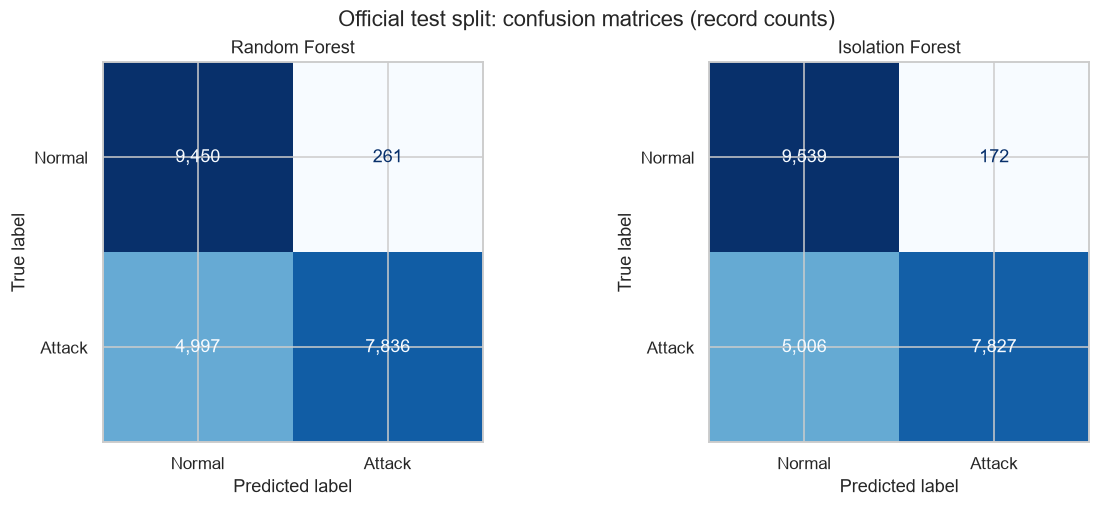

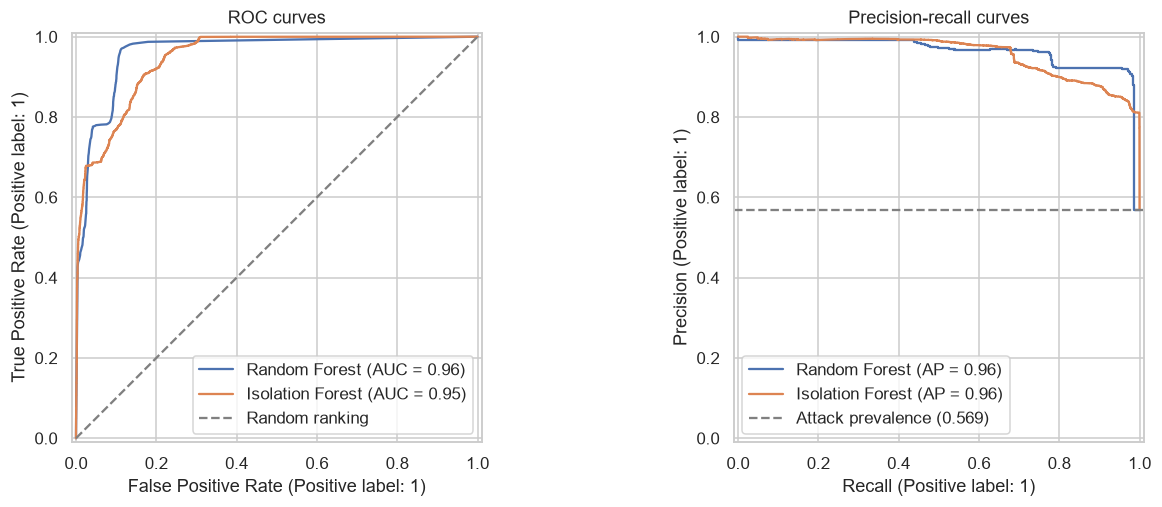

In [8]:
figures = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
for ax, (model_name, result) in zip(axes, models.items()):
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, result['predictions'], labels=[0, 1], display_labels=['Normal', 'Attack'],
        cmap='Blues', colorbar=False, values_format=',d', ax=ax,
    )
    ax.set_title(model_name)
fig.suptitle('Official test split: confusion matrices (record counts)')
figures['confusion_matrices'] = fig
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for model_name, result in models.items():
    metrics.RocCurveDisplay.from_predictions(y_test, result['scores'], name=model_name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, result['scores'], name=model_name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
axes[0].set_title('ROC curves')
axes[0].legend(loc='lower right')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray', label=f'Attack prevalence ({y_test.mean():.3f})')
axes[1].set_title('Precision-recall curves')
axes[1].legend(loc='lower left')
figures['roc_and_precision_recall'] = fig
plt.show()

## 8. Per-Category Recall and Unseen Attacks

This is the main comparison for attack coverage. For each attack family, detection
recall is the fraction of its records predicted as **attack**, regardless of the
specific attack name. For Normal, the corresponding correct-detection rate is
**specificity**, the fraction predicted normal. This is not five-class classification.

Show sample counts alongside rates, especially for small U2R and individual attack
types. **Pooled recall** weights attack types by their record counts; **macro recall**
gives every attack type equal weight. Report both for seen and unseen attack names.
Interpret higher recall alongside normal FPR; a detector that alarms more often can
catch more attacks while creating a larger operational burden.

,,model,Isolation Forest,Random Forest
category,metric,support,,
Normal,specificity,9711,0.9823,0.9731
DoS,attack_recall,7458,0.7597,0.7816
Probe,attack_recall,2421,0.8373,0.7534
R2L,attack_recall,2887,0.0423,0.0599
U2R,attack_recall,67,0.1791,0.1493


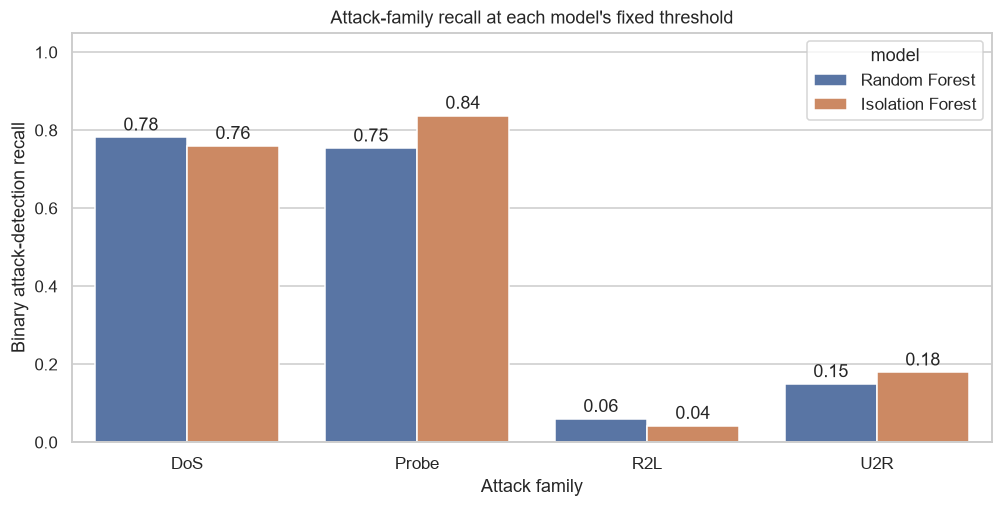

In [9]:
family_rows = []
for family in FAMILY_ORDER:
    mask = (test_df['attack_family'] == family).to_numpy()
    for model_name, result in models.items():
        target = NORMAL_LABEL if family == 'Normal' else ATTACK_LABEL
        rate = float(np.mean(result['predictions'][mask] == target)) if mask.any() else np.nan
        family_rows.append({
            'category': family, 'support': int(mask.sum()), 'model': model_name,
            'metric': 'specificity' if family == 'Normal' else 'attack_recall',
            'value': rate,
        })
family_results = pd.DataFrame(family_rows)
family_table = family_results.pivot(index=['category', 'metric', 'support'], columns='model', values='value')
family_table = family_table.reindex(FAMILY_ORDER, level='category')
display(family_table.round(4))

attack_family_results = family_results[family_results['metric'] == 'attack_recall']
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
sns.barplot(data=attack_family_results, x='category', y='value', hue='model',
            order=FAMILY_ORDER[1:], errorbar=None, ax=ax)
ax.set(ylim=(0, 1.05), xlabel='Attack family', ylabel='Binary attack-detection recall',
       title="Attack-family recall at each model's fixed threshold")
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2)
figures['attack_family_recall'] = fig
plt.show()

All test attack types (binary detection recall):


,,,model,Isolation Forest,Random Forest
attack_type,family,unseen_in_training,support,,
apache2,DoS,True,737,0.7069,0.1343
back,DoS,False,359,0.0000,0.9610
buffer_overflow,U2R,False,20,0.2500,0.1500
ftp_write,R2L,False,3,0.0000,0.3333
guess_passwd,R2L,False,1231,0.0211,0.0000
httptunnel,R2L,True,133,0.6241,0.0677
imap,R2L,False,1,1.0000,0.0000
ipsweep,Probe,False,141,0.0426,1.0000
land,DoS,False,7,1.0000,0.8571


Attack types absent from training:


,,model,Isolation Forest,Random Forest
attack_type,family,support,,
apache2,DoS,737,0.7069,0.1343
httptunnel,R2L,133,0.6241,0.0677
mailbomb,DoS,293,0.0000,0.0000
mscan,Probe,996,0.9207,0.4046
named,R2L,17,0.1765,0.1176
processtable,DoS,685,0.3606,0.0088
ps,U2R,15,0.0667,0.1333
saint,Probe,319,0.6426,0.9875
sendmail,R2L,14,0.0000,0.0000


support  attack_type_count  \
group               model                                          
Seen attack types   Random Forest        9083                 20   
                    Isolation Forest     9083                 20   
Unseen attack types Random Forest        3750                 17   
                    Isolation Forest     3750                 17   

                                      pooled_recall  macro_type_recall  
group               model                                               
Seen attack types   Random Forest            0.7699             0.5765  
                    Isolation Forest         0.6436             0.3742  
Unseen attack types Random Forest            0.2248             0.2256  
                    Isolation Forest         0.5283             0.2340

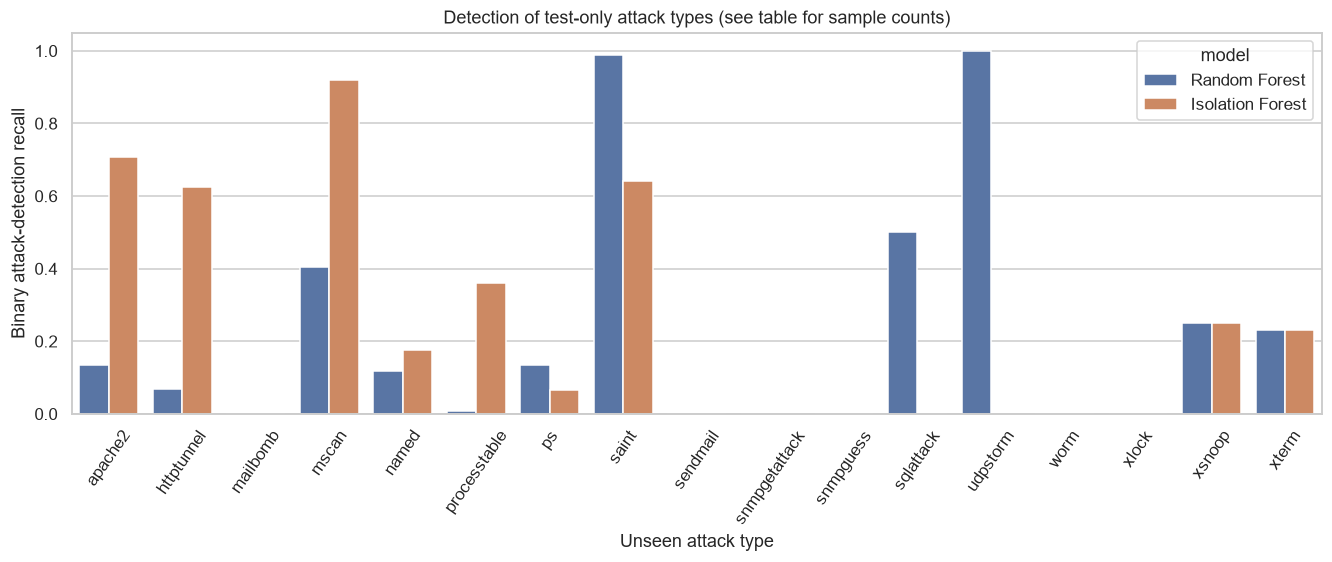

Read these results together:
Random Forest: family-macro recall=0.436, unseen pooled recall=0.225, unseen type-macro recall=0.226, normal FPR=0.027.
Isolation Forest: family-macro recall=0.455, unseen pooled recall=0.528, unseen type-macro recall=0.234, normal FPR=0.018.
Family comparison: positive delta favors RF; negative delta favors IF.


,category,support,Isolation Forest,Random Forest,rf_minus_if_percentage_points,higher_recall
0,DoS,7458,0.7597,0.7816,2.1856,Random Forest
1,Probe,2421,0.8373,0.7534,-8.3850,Isolation Forest
2,R2L,2887,0.0423,0.0599,1.7665,Random Forest
3,U2R,67,0.1791,0.1493,-2.9851,Isolation Forest


Higher recall must be considered alongside normal false-positive rate.
These are test results, not a basis for retuning thresholds or model settings.


In [10]:
attack_type_rows = []
for attack_type in sorted(test_attack_types):
    mask = (test_df['label'] == attack_type).to_numpy()
    for model_name, result in models.items():
        attack_type_rows.append({
            'attack_type': attack_type,
            'family': ATTACK_FAMILY_MAP[attack_type],
            'unseen_in_training': attack_type in unseen_attack_types,
            'support': int(mask.sum()), 'model': model_name,
            'recall': float(np.mean(result['predictions'][mask] == ATTACK_LABEL)),
        })
attack_type_results = pd.DataFrame(attack_type_rows)
attack_type_table = attack_type_results.pivot(
    index=['attack_type', 'family', 'unseen_in_training', 'support'], columns='model', values='recall'
)
print('All test attack types (binary detection recall):')
display(attack_type_table.round(4))

unseen_type_results = attack_type_results[attack_type_results['unseen_in_training']].copy()
print('Attack types absent from training:')
display(unseen_type_results.pivot(
    index=['attack_type', 'family', 'support'], columns='model', values='recall'
).round(4))

attack_group_rows = []
for group_name, mask in {
    'Seen attack types': (y_test == ATTACK_LABEL) & ~unseen_attack_mask,
    'Unseen attack types': unseen_attack_mask,
}.items():
    group_types = set(test_df.loc[mask, 'label'])
    for model_name, result in models.items():
        type_rates = attack_type_results.loc[
            (attack_type_results['model'] == model_name) &
            attack_type_results['attack_type'].isin(group_types), 'recall'
        ]
        attack_group_rows.append({
            'group': group_name, 'model': model_name, 'support': int(mask.sum()),
            'attack_type_count': len(group_types),
            'pooled_recall': float(np.mean(result['predictions'][mask] == ATTACK_LABEL)) if mask.any() else np.nan,
            'macro_type_recall': float(type_rates.mean()) if len(type_rates) else np.nan,
        })
attack_group_results = pd.DataFrame(attack_group_rows)
display(attack_group_results.set_index(['group', 'model']).round(4))

if not unseen_type_results.empty:
    fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
    sns.barplot(data=unseen_type_results, x='attack_type', y='recall', hue='model',
                order=unseen_attack_types, errorbar=None, ax=ax)
    ax.set(ylim=(0, 1.05), xlabel='Unseen attack type', ylabel='Binary attack-detection recall',
           title='Detection of test-only attack types (see table for sample counts)')
    ax.tick_params(axis='x', rotation=55)
    figures['unseen_attack_recall'] = fig
    plt.show()

print('Read these results together:')
for model_name in models:
    row = overall_results.set_index('model').loc[model_name]
    unseen_row = attack_group_results.loc[
        (attack_group_results['model'] == model_name) &
        (attack_group_results['group'] == 'Unseen attack types')
    ].iloc[0]
    family_macro = attack_family_results.loc[attack_family_results['model'] == model_name, 'value'].mean()
    print(f"{model_name}: family-macro recall={family_macro:.3f}, "
          f"unseen pooled recall={unseen_row['pooled_recall']:.3f}, "
          f"unseen type-macro recall={unseen_row['macro_type_recall']:.3f}, "
          f"normal FPR={row['normal_fpr']:.3f}.")

# Add category coverage to the overall CSV for the later Transformer comparison.
family_macro_by_model = attack_family_results.groupby('model')['value'].mean()
unseen_summary = attack_group_results.loc[
    attack_group_results['group'] == 'Unseen attack types'
].set_index('model')
overall_results['macro_attack_family_recall'] = overall_results['model'].map(family_macro_by_model)
overall_results['unseen_attack_recall'] = overall_results['model'].map(unseen_summary['pooled_recall'])
overall_results['macro_unseen_attack_type_recall'] = overall_results['model'].map(unseen_summary['macro_type_recall'])
overall_results['unseen_attack_support'] = int(unseen_attack_mask.sum())
overall_results['unseen_attack_type_count'] = len(unseen_attack_types)

family_comparison = attack_family_results.pivot(
    index=['category', 'support'], columns='model', values='value'
).reindex(FAMILY_ORDER[1:], level='category').reset_index()
family_comparison.columns.name = None
recall_delta = family_comparison['Random Forest'] - family_comparison['Isolation Forest']
family_comparison['rf_minus_if_percentage_points'] = 100 * recall_delta
family_comparison['higher_recall'] = np.where(
    np.isclose(recall_delta, 0, rtol=0, atol=1e-12), 'Tie',
    np.where(recall_delta > 0, 'Random Forest', 'Isolation Forest'),
)
print('Family comparison: positive delta favors RF; negative delta favors IF.')
display(family_comparison.round(4))
print('Higher recall must be considered alongside normal false-positive rate.')
print('These are test results, not a basis for retuning thresholds or model settings.')

## 9. Random Forest Feature Importance

Inspect training-derived impurity importances for encoded columns and also sum
one-hot importances back to each original input feature. Check that network
traffic features drive the classifier and that target/difficulty fields are absent.
Constant inputs should have zero importance.

These are exploratory associations, not causal explanations. Impurity importance
can favor continuous or high-cardinality features; aggregation improves readability
but does not remove that bias. Avoid changing the model after inspecting test results.

,source_feature,importance
0,src_bytes,0.13067
1,dst_bytes,0.10963
2,flag,0.08726
3,service,0.07758
4,same_srv_rate,0.05717
5,dst_host_srv_count,0.05335
6,dst_host_same_srv_rate,0.04234
7,count,0.04083
8,protocol_type,0.04045
9,diff_srv_rate,0.04035


Constant-column importance:


,source_feature,importance
40,num_outbound_cmds,0.0


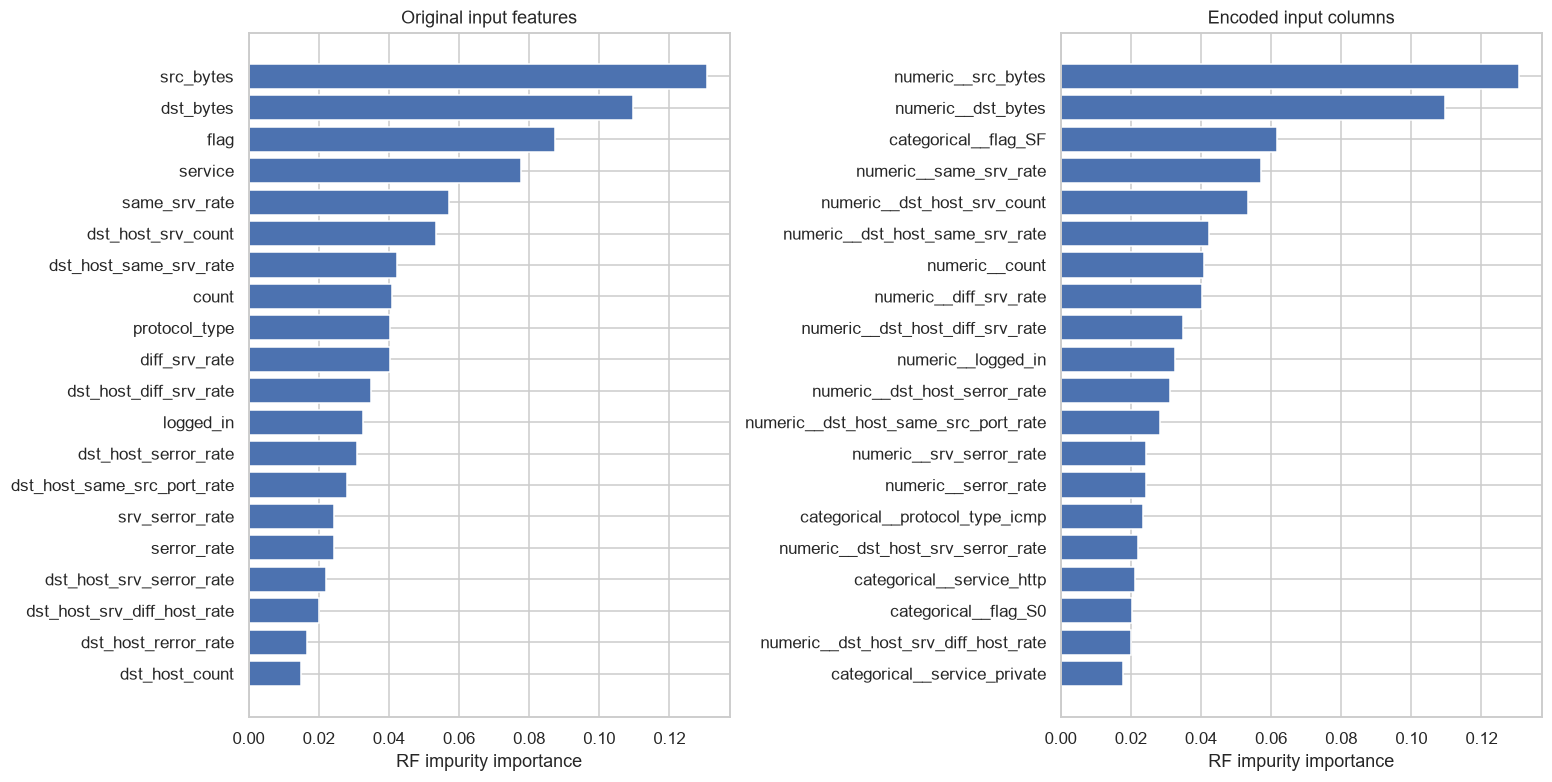

In [11]:
rf_encoder = rf_preprocessor.named_transformers_['categorical']
source_features = [
    column
    for column, categories in zip(CATEGORICAL_COLUMNS, rf_encoder.categories_)
    for _ in categories
] + NUMERIC_COLUMNS
assert len(source_features) == len(rf_feature_names) == len(rf_model.feature_importances_)

feature_importance = pd.DataFrame({
    'encoded_feature': rf_feature_names,
    'source_feature': source_features,
    'importance': rf_model.feature_importances_,
}).sort_values('importance', ascending=False, ignore_index=True)
original_feature_importance = (
    feature_importance.groupby('source_feature', as_index=False)['importance'].sum()
    .sort_values('importance', ascending=False, ignore_index=True)
)
assert set(original_feature_importance['source_feature']) == set(RAW_FEATURE_COLUMNS)
assert np.isclose(original_feature_importance['importance'].sum(), 1.0)
display(original_feature_importance.head(20).round(5))
print('Constant-column importance:')
display(original_feature_importance[original_feature_importance['source_feature'].isin(constant_columns)])

fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
for ax, table, label, title in [
    (axes[0], original_feature_importance, 'source_feature', 'Original input features'),
    (axes[1], feature_importance, 'encoded_feature', 'Encoded input columns'),
]:
    top = table.head(20).iloc[::-1]
    ax.barh(top[label], top['importance'])
    ax.set(xlabel='RF impurity importance', title=title)
figures['rf_feature_importance'] = fig
plt.show()

## 10. Save Results for the Transformer Comparison

Write **`results/baseline_overall.csv`** with one row per model and experiment
identity (task, seed, and train/test file hashes). Rerunning replaces matching
baseline rows and preserves other models, including a future Transformer row.
Also save per-category, per-attack, unseen-attack, and feature-importance tables;
aligned test predictions; figures; and a JSON experiment manifest.

For a fair future comparison, use these exact train/test files, binary label
convention, test row coverage, and metric definitions. Fit and tune using training
data only. A sequence model that omits test rows needs a separately documented
evaluation protocol. Score scales and model thresholds can differ, so always
compare recall alongside normal false-positive rate and ranking metrics.

In [12]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR = RESULTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
train_sha256, test_sha256 = file_sha256(TRAIN_PATH), file_sha256(TEST_PATH)
run_timestamp = datetime.now(timezone.utc).isoformat()
overall_export = overall_results.assign(
    task='binary_intrusion_detection', seed=SEED,
    train_file=TRAIN_PATH.name, test_file=TEST_PATH.name,
    train_sha256=train_sha256, test_sha256=test_sha256,
    train_rows=len(train_df), test_rows=len(test_df), positive_label=ATTACK_LABEL,
    threshold_operator='>', run_timestamp_utc=run_timestamp,
)
comparison_keys = ['model', 'task', 'seed', 'train_sha256', 'test_sha256']
if BASELINE_RESULTS_PATH.exists():
    previous_results = pd.read_csv(BASELINE_RESULTS_PATH)
    missing_keys = set(comparison_keys) - set(previous_results.columns)
    if missing_keys:
        raise ValueError(f'Existing results lack identity columns {sorted(missing_keys)}; file preserved.')
    previous_keys = pd.MultiIndex.from_frame(previous_results[comparison_keys])
    current_keys = pd.MultiIndex.from_frame(overall_export[comparison_keys])
    saved_overall = pd.concat([
        previous_results.loc[~previous_keys.isin(current_keys)], overall_export,
    ], ignore_index=True, sort=False)
else:
    saved_overall = overall_export.copy()

temporary_csv = BASELINE_RESULTS_PATH.with_suffix('.csv.tmp')
saved_overall.to_csv(temporary_csv, index=False)
temporary_csv.replace(BASELINE_RESULTS_PATH)

test_predictions = pd.DataFrame({
    'test_row': np.arange(len(test_df)),
    'label': test_df['label'].to_numpy(),
    'attack_family': test_df['attack_family'].astype(str).to_numpy(),
    'binary_label': y_test, 'unseen_attack_type': unseen_attack_mask,
    'rf_attack_probability': rf_scores, 'rf_prediction': rf_predictions,
    'if_anomaly_score': if_scores, 'if_prediction': if_predictions,
})
tables_to_save = {
    'baseline_family_recall.csv': family_results,
    'baseline_family_comparison.csv': family_comparison,
    'baseline_attack_type_recall.csv': attack_type_results,
    'baseline_unseen_attack_recall.csv': unseen_type_results,
    'baseline_attack_groups.csv': attack_group_results,
    'baseline_rf_feature_importance.csv': feature_importance,
    'baseline_rf_original_feature_importance.csv': original_feature_importance,
    'baseline_test_predictions.csv': test_predictions,
}
for filename, table in tables_to_save.items():
    table.to_csv(RESULTS_DIR / filename, index=False)
for figure_name, figure in figures.items():
    figure.savefig(FIGURES_DIR / f'{figure_name}.png', dpi=160, bbox_inches='tight')

manifest = {
    'task': 'binary_intrusion_detection', 'seed': SEED,
    'run_timestamp_utc': run_timestamp,
    'dataset': {
        'train_file': TRAIN_PATH.name, 'test_file': TEST_PATH.name,
        'train_sha256': train_sha256, 'test_sha256': test_sha256,
        'train_rows': len(train_df), 'test_rows': len(test_df),
        'test_rows_matching_train_features': overlap_rows,
        'official_split_preserved': True,
    },
    'labels': {'normal': NORMAL_LABEL, 'attack': ATTACK_LABEL},
    'attack_family_map': ATTACK_FAMILY_MAP,
    'unseen_attack_types': unseen_attack_types,
    'unseen_attack_test_rows': int(unseen_attack_mask.sum()),
    'features': {
        'raw_feature_columns': RAW_FEATURE_COLUMNS,
        'categorical_columns': CATEGORICAL_COLUMNS, 'numeric_columns': NUMERIC_COLUMNS,
        'excluded_columns': sorted(EXCLUDED_COLUMNS), 'constant_training_columns': constant_columns,
        'encoding': 'one_hot_handle_unknown_ignore', 'numeric_scaling': 'StandardScaler',
        'rf_fit_scope': 'full_official_training_set',
        'if_fit_scope': 'normal_fit_subset_only_excludes_calibration',
        'rf_encoded_feature_names': rf_feature_names.tolist(),
        'if_encoded_feature_names': if_preprocessor.get_feature_names_out().tolist(),
    },
    'random_forest': {
        'parameters': rf_model.get_params(), 'threshold': RF_THRESHOLD,
        'threshold_operator': '>', 'score': 'attack_probability',
    },
    'isolation_forest': {
        'parameters': if_model.get_params(), 'score': 'negative_score_samples',
        'normal_fit_rows': len(if_fit_indices), 'normal_calibration_rows': len(if_calibration_indices),
        'calibration_fraction': IF_CALIBRATION_FRACTION, 'target_calibration_fpr': IF_TARGET_FPR,
        'actual_calibration_fpr': if_calibration_fpr, 'threshold': if_threshold,
        'threshold_operator': '>', 'quantile_method': 'higher',
        'normal_fit_indices': if_fit_indices.tolist(),
        'normal_calibration_indices': if_calibration_indices.tolist(),
    },
    'metric_definitions': {
        'positive_class': 'attack', 'family_recall': 'binary attack detection within each attack family',
        'normal_category_rate': 'specificity', 'normal_fpr': 'FP / (TN + FP)',
        'average_precision': 'sklearn average_precision_score, not trapezoidal PR AUC',
        'pooled_unseen_recall': 'fraction of unseen attack records predicted attack',
        'macro_unseen_recall': 'unweighted mean of per-unseen-attack-type recall',
        'macro_attack_family_recall': 'unweighted mean of supported DoS/Probe/R2L/U2R recall; excludes Normal',
        'unseen_attack_recall': 'pooled recall on attack names absent from training',
        'macro_unseen_attack_type_recall': 'unweighted mean of per-unseen-attack-type recall',
        'fit_seconds': 'estimator fit only; excludes preprocessing and calibration',
        'predict_seconds': 'estimator test scoring and thresholding; excludes preprocessing',
    },
    'versions': {
        'python': platform.python_version(), 'numpy': np.__version__,
        'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    },
}
(RESULTS_DIR / 'baseline_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(f'Saved overall comparison: {BASELINE_RESULTS_PATH}')
print(f'Saved {len(tables_to_save)} supporting tables, {len(figures)} figures, and the experiment manifest.')
display(saved_overall[[
    'model', 'f1', 'recall', 'normal_fpr', 'macro_attack_family_recall',
    'unseen_attack_recall', 'macro_unseen_attack_type_recall',
]].round(4))

Saved overall comparison: C:\Users\majah\OneDrive\Desktop\TRANSFORMER\results\baseline_overall.csv
Saved 8 supporting tables, 5 figures, and the experiment manifest.


,model,f1,recall,normal_fpr,macro_attack_family_recall,unseen_attack_recall,macro_unseen_attack_type_recall
0,Random Forest,0.7488,0.6106,0.0269,0.4360,0.2248,0.2256
1,Isolation Forest,0.7514,0.6099,0.0177,0.4546,0.5283,0.2340


### Reading the Completed Experiment

- Start with family recall and unseen-attack recall, then check the normal false-positive rate.
- Use ROC AUC and average precision to compare ranking quality across score thresholds.
- Tiny attack categories have uncertain rates; their sample counts are part of the result.
- The official dataset contains some matching train/test feature vectors, as reported above.
- This experiment measures performance on NSL-KDD; it does not establish performance on live traffic.
- Keep this test split for reporting. Further model/threshold choices need training-only validation.